# K means clustering

## import necessary libraries

In [4]:
import pandas as pd
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import AgglomerativeClustering,KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import  accuracy_score,classification_report,confusion_matrix,recall_score,roc_auc_score,precision_score,roc_curve
from sklearn.ensemble import GradientBoostingClassifier,AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## Data collection

In [3]:
college_data = pd.read_csv("college_list.csv")
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9
...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6


## 3.data understanding

In [5]:
college_data.shape

(500, 6)

In [6]:
college_data.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [7]:
college_data.dtypes

College_Name              object
Student_Faculty_Ratio      int64
Annual_Fees_INR            int64
Placement_Percentage       int64
Average_Package_LPA      float64
Infrastructure_Score       int64
dtype: object

## 4.data properation

In [8]:
X=college_data.drop(labels="College_Name" ,axis= 1)

In [9]:
std=StandardScaler()
scaled_x=std.fit_transform(X)
scaled_x=pd.DataFrame(data=scaled_x)
scaled_x

,0,1,2,3,4
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


## 5.model building

In [19]:
cluster_KM=KMeans( n_clusters=3,random_state=12)
cluster_KM

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,12
,copy_x,True
,algorithm,'lloyd'


In [20]:
cluster_KM.fit(scaled_x)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,12
,copy_x,True
,algorithm,'lloyd'


In [21]:
cluster_KM.labels_

array([2, 0, 0, 0, 2, 1, 1, 0, 2, 1, 1, 1, 0, 2, 1, 1, 2, 0, 1, 2, 1, 2,
       2, 0, 1, 1, 2, 0, 0, 0, 0, 1, 1, 2, 2, 1, 1, 0, 2, 1, 1, 1, 1, 0,
       1, 0, 2, 0, 1, 2, 2, 1, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 1, 0, 2, 0,
       1, 1, 2, 0, 2, 1, 0, 0, 1, 2, 1, 0, 0, 2, 1, 2, 0, 1, 1, 1, 1, 2,
       2, 2, 2, 1, 1, 0, 0, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 0, 1, 2, 2,
       0, 2, 2, 0, 2, 0, 2, 2, 2, 2, 0, 1, 2, 2, 2, 0, 2, 2, 1, 0, 0, 0,
       0, 0, 1, 0, 2, 2, 2, 1, 0, 0, 2, 1, 1, 0, 0, 2, 2, 0, 0, 2, 0, 0,
       0, 1, 1, 2, 2, 1, 1, 1, 2, 2, 2, 1, 2, 2, 2, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 2, 2, 2, 1, 2, 0, 0, 1, 2, 2, 1, 2, 2, 2, 0, 2, 0, 2,
       2, 2, 1, 1, 1, 2, 1, 2, 1, 0, 1, 1, 1, 2, 2, 2, 1, 2, 0, 2, 0, 1,
       1, 1, 1, 0, 1, 2, 2, 1, 0, 0, 1, 1, 0, 1, 1, 2, 0, 1, 0, 0, 2, 2,
       0, 0, 2, 2, 1, 2, 2, 0, 1, 0, 1, 1, 0, 2, 0, 1, 1, 1, 2, 2, 0, 1,
       1, 0, 2, 1, 0, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 1, 0, 1, 1, 1, 2, 2,
       1, 2, 0, 0, 1, 0, 1, 0, 2, 2, 1, 0, 0, 1, 2,

## Clustering is done

## level 2 - data mining - which is clusterining

In [22]:
college_data["Collge_Level"]=cluster_KM
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Collge_Level
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8,"KMeans(n_clusters=3, random_state=12)"
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,"KMeans(n_clusters=3, random_state=12)"
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,"KMeans(n_clusters=3, random_state=12)"
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,"KMeans(n_clusters=3, random_state=12)"
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,"KMeans(n_clusters=3, random_state=12)"
...,...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5,"KMeans(n_clusters=3, random_state=12)"
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7,"KMeans(n_clusters=3, random_state=12)"
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3,"KMeans(n_clusters=3, random_state=12)"
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6,"KMeans(n_clusters=3, random_state=12)"


In [23]:
cluster_KM.cluster_centers_

array([[ 0.80005965, -0.35292454,  0.06058015, -0.06989436,  0.7879027 ],
       [ 0.33899088,  0.07714374,  0.32735611,  0.04780598, -1.0553563 ],
       [-0.9460557 ,  0.21270177, -0.34396936,  0.0127609 ,  0.32235082]])

In [28]:
X["Collge_Level"]=cluster_KM.labels_
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Collge_Level
0,14,113042,59,9.20,8,2
1,27,115999,67,3.07,7,0
2,22,47955,50,3.40,9,0
3,18,67841,43,4.64,8,0
4,15,100640,54,4.66,9,2
...,...,...,...,...,...,...
495,17,106323,56,9.33,5,2
496,12,39111,76,3.62,7,2
497,16,199182,64,3.88,3,1
498,10,46389,77,9.31,6,2


In [30]:
X.groupby(by="Collge_Level").agg(["mean"])


,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,mean,mean,mean,mean,mean
Collge_Level,,,,,
0,23.425676,116224.283784,70.040541,6.787973,7.554054
1,20.347305,143690.473054,74.622754,7.131078,3.862275
2,11.767568,152347.848649,63.091892,7.028919,6.621622


In [31]:
X.groupby(by="Collge_Level").agg(["min","max"])


Student_Faculty_Ratio     Annual_Fees_INR          \
                               min max             min     max   
Collge_Level                                                     
0                               14  29           30404  249536   
1                                8  29           31605  248803   
2                                8  22           31015  249930   

             Placement_Percentage     Average_Package_LPA         \
                              min max                 min    max   
Collge_Level                                                       
0                              40  99                2.00  11.99   
1                              40  99                2.01  11.96   
2                              40  99                2.01  11.91   

             Infrastructure_Score      
                              min max  
Collge_Level                           
0                               5   9  
1                               3   6  
2                               3   9

In [32]:
clusters_name={0:"BEST",1:"MID",2:"EMERGING"}
X["Collge Catogaries"]=X["Collge_Level"].map(clusters_name)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Collge_Level,Collge Catogaries
0,14,113042,59,9.20,8,2,EMERGING
1,27,115999,67,3.07,7,0,BEST
2,22,47955,50,3.40,9,0,BEST
3,18,67841,43,4.64,8,0,BEST
4,15,100640,54,4.66,9,2,EMERGING
...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,2,EMERGING
496,12,39111,76,3.62,7,2,EMERGING
497,16,199182,64,3.88,3,1,MID
498,10,46389,77,9.31,6,2,EMERGING


## level 3 - to supervised stpes

## how to decide how many clusters for optimal

In [40]:
wcss = []
for i in range(1,11):
    Kmeans = KMeans( n_clusters=i,random_state=1234)
    Kmeans.fit(scaled_x)
    wcss.append(Kmeans.inertia_)

In [41]:
wcss

[2500.0,
 2128.174524152105,
 1842.6711981098247,
 1630.4255355593127,
 1558.7124859131056,
 1404.5714789757476,
 1282.6375220837544,
 1229.5378438851774,
 1130.029607219633,
 1088.5708994498423]

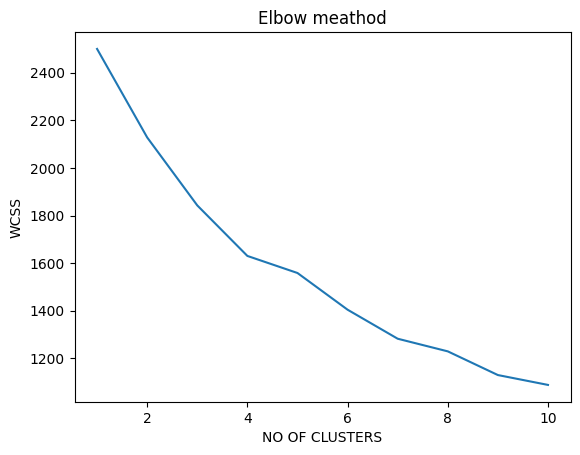

In [42]:
plt.plot(range(1,11),wcss)
plt.title("Elbow meathod")
plt.xlabel("NO OF CLUSTERS")
plt.ylabel("WCSS")
plt.show()

## TASK
1. silhotee scire
2. calinski harabarz score
3. IRIS DATASET _ CLUSTERING